In [1]:
import os, sys, tempfile, subprocess
from coffea import processor
from coffea.nanoevents import NanoAODSchema, NanoEventsFactory
import matplotlib.pyplot as plt
import yaml

sidm_path = str(os.getcwd()).split('/sidm')[0]
if sidm_path not in sys.path:
    sys.path.insert(1, sidm_path)

from sidm.tools import utilities, scaleout, sidm_processor, llpnanoaodschema
from sidm.studies.cosmicVeto import functions
from sidm.studies.dy_jets import function_dy

utilities.set_plot_style()
%matplotlib inline

In [2]:
channels=  [ 
    "cr_Zmumu_noLJ_jet",
    # "cr_Zmumu_noLJ_prompt",
    # "cr_Zmumu_noLJ_displaced",
           ]

samples_separate = ["TTJets",
               "DYJetsToLL",
               "QCD",
               "Diboson",
              # "data"
              ]
samples = ["bgs", "data", "TTJets",
               "DYJetsToLL",
               "QCD",
               "Diboson",]
sum_hist= {}
for channel_name in channels:
    sum_hist[channel_name] = {}
for s in samples:
    if s == "data":
        list1= functions.get_data_files()
        list1 =  [x for x in list1 if "C" in x]
    elif s == "bgs":
        list1=[]
        for y in samples_separate:
            list2 = functions.get_bg_file_names(y)
            list1.extend(list2)
    else:
        list1 = functions.get_bg_file_names(s)
    for channel_name in channels:
        folder_name = f"OutputFiles/{channel_name}"
        sum_h= utilities.sum_hist(list1, folder_name)
        sum_hist[channel_name][s] = sum_h



In [3]:
sum_hist[channel_name][s].keys()

dict_keys(['muon_trkNumPixelHits', 'mu_lj_pfMu_max_trkNumPixelHits', 'mu_lj_pfMu_min_trkNumPixelHits', 'mu_lj_pfMu_min_trkNumTrkLayers', 'muon_muon_invmass', 'muon_muon_invmass_highRange', 'muon_n', 'electron_n', 'dsaMuon_n', 'photon_n', 'mu_lj_mass', 'mu0_mu1_dphi_invMass', 'mu_mu_dphi_invMass', 'mu_mu_dphi', 'mu_mu_inv_mass', 'jet_n', 'jet_pt', 'jet_eta_phi', 'muon_pt', 'muon_eta_phi', 'muN_muLj_muN_diff', 'mu_lj_muonN', 'mu_lj_pfMu_n', 'mu_lj_dsaMu_n', 'mu_lj_pt', 'mu_lj_muon_pt', 'mu_lj_pfMuon_pt', 'mu_lj_dsaMuon_pt', 'jet0Pt_muLj0_pt', 'jet0_muLj0_dPhi', 'mu0_mu1_dphi', 'mu0_mu1_dR', 'jet0_muLj0_dR', 'jet1_muLj0_dR', 'jet1_muLj0_dPhi', 'jet1Pt_muLj0_pt', 'mu0_mu1_pt', 'jet0Pt_diMuon_dR', 'jet0Pt_diMuon_pt', 'jet0Pt_diMuon_dPhi', 'muon_dthits_cschits', 'muon_dthits_cschits_leading', 'mu_lj_eta_phi', 'egm_lj_eta_phi', 'muon_dthits_plus_cschits', 'muon_dthits_plus_cschits_leading_vs_dR', 'muon_dthits_plus_cschits_subleading_vs_dR', 'muon_dthits_plus_cschits_leading_vs_dR_event_mask',

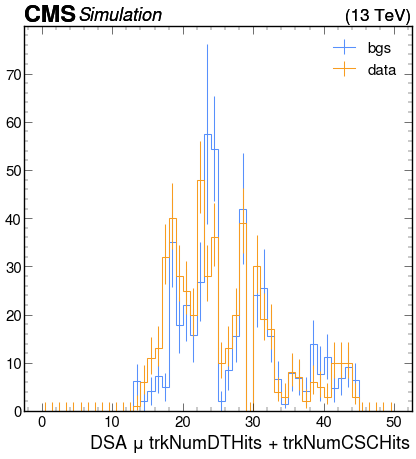

In [7]:
r = 6.616/62.061775847

histogram_name = "dsaMuon_dthits_plus_cschits"
for channel_name in channels:
    for s in ["bgs", "data"]:
        if s == "bgs":
            histogram = r*sum_hist[channel_name][s][histogram_name][channel_name, :]
        else:
            histogram =sum_hist[channel_name][s][histogram_name][channel_name, :]
        utilities.plot(histogram, label = s )
plt.legend()